# 04 — Microglia states (Tangram probabilities) × compartments × condition

Input: `../data/microglia_tangram.h5ad` from notebook 03 (per-cell state probabilities in `obsm['state_prob']`)

**Questions**
1. Does the microglial state profile differ between groups, over the whole brain and within compartments 3 and 10?
2. Are microglia near DA-oligodendrocytes in a different state than microglia further away, more so in responders?
3. Are the results robust to the choice of another methods (the classifier)?

### Why notebook 03 called almost every microglia "uncertain"
Nothing broke; a 0.5 threshold does not fit what Tangram returns (according to claude):
- **Tangram is a soft mapping.** Each Xenium cell receives a weighted mix of many atlas cells, so its state probability
  is an average. With 8 states the median highest probability is 0.26; a 0.5 cut-off keeps 1.6% of cells.
- **The level of the probabilities is set by the reference.** The mean probability of each state equals its share in the
  subsampled atlas (~0.15 each with the 3,000-per-state cap; Cytokine 0.011 = 213 of 19,788 atlas cells).
- **The probabilities still carry signal**: r = 0.28–0.41 with marker scores measured directly in Xenium.
- With ~600 transcripts per microglia, single-cell state calls are weak for any method.

So: no per-cell labels. Each state probability is a continuous score, averaged per mouse.

### Statistics
- **Primary: PERMANOVA**: PERMANOVA on the per-mouse state profile (centred log-ratio of the mean
  probabilities, which form a composition), with exact permutation p-values. It is a one-way ANOVA on all 8 states at
  once, without normality assumptions (n = 3 per group is too small). Three designs:
  - mtDSB vs control, labels permuted within timepoint (400 relabelings, min p = 0.005);
  - responder vs control (84 relabelings, min p = 0.012);
  - control / non-responder / responder, within timepoint (3,600 relabelings).
- **Per-state tests** (which states drive a difference): exact permutation of the mean probability

In [2]:
import h5py
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from anndata.io import read_elem
from scipy.spatial import cKDTree
import compartment_stats as cs

MG = '../data/microglia_tangram.h5ad'
FULL = '../data/adata_5k_cellcharter.h5ad'
ATLAS = '../data/Mouse_Myeloid_atlas_v1.h5ad'
RES = '../results/cellcharter/tangram'
SAMPLE, COND, COMP, CT_WORK, TP, RESP = 'sample_id', 'condition', 'compartment', 'cell_class_work', 'timepoint', 'responder_status'
MIN_MG = 50
PRIMARY = ['3', '10']
RADIUS = 50

q = ad.read_h5ad(MG)
P = pd.DataFrame(q.obsm['state_prob'], index=q.obs_names, columns=list(q.uns['state_prob_columns']))
STATES = list(P.columns)
prior = P.mean()                                   # = state shares of the subsampled atlas
print(pd.DataFrame({'mean probability (= reference share)': prior.round(3)}))

info = cs.sample_table(q.obs, SAMPLE, [COND, TP, RESP])
info['_all'] = 'all'
COMPARISONS = {
    'mtDSB vs control': dict(cond_key=COND, treat='mtDSB', ref='control', strata_key=TP),           # primary
    'responder vs control': dict(cond_key=RESP, treat='responder', ref='control', strata_key='_all'),  # secondary
}
DESIGNS = {
    'mtDSB vs control': (COND, ['control', 'mtDSB'], TP),
    'responder vs control': (RESP, ['control', 'responder'], '_all'),
    'control / non-responder / responder': (RESP, ['control', 'non-responder', 'responder'], TP),
}
PALETTE, TP_MARKERS = cs.GROUP_COLOURS, cs.TP_MARKERS      # colour = responder status, marker = timepoint

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


                 mean probability (= reference share)
Cytokine                                        0.011
IFN                                             0.148
Inflammation                                    0.155
MHC                                             0.120
Neuroprotection                                 0.107
Phagocytosis                                    0.152
Proliferation                                   0.151
Surveillance                                    0.156


In [3]:
def mouse_means(values, by=None, min_cells=MIN_MG):
    # mean of each column per mouse (and per `by` group); NaN where fewer than min_cells microglia
    keys = [q.obs[SAMPLE]] + ([q.obs[by]] if by else [])
    g = values.groupby(keys, observed=True)
    m = g.mean()
    m.loc[g.size() < min_cells] = np.nan
    return m


def test_means(m, by=None):
    # per-state exact permutation tests; m indexed by sample (or sample x by)
    rows = []
    groups = [('all microglia', m)] if by is None else list(m.groupby(level=by, observed=True))
    for key, mm in groups:
        if by is not None:
            mm = mm.droplevel(by)
        for name, kw in COMPARISONS.items():
            i = info.loc[mm.index]
            keep = i[kw['cond_key']].isin([kw['treat'], kw['ref']]).values
            mk, ik = mm[keep], i[keep]
            is_t = (ik[kw['cond_key']] == kw['treat']).values
            for st in mk.columns:
                y = mk[st]
                if y[is_t].notna().sum() < 3 or y[~is_t].notna().sum() < 3:
                    continue
                r = cs.stratified_permutation_test(y, ik[kw['cond_key']], ik[kw['strata_key']], kw['treat'], kw['ref'])
                rows.append({'comparison': name, 'scope': key, 'state': st,
                             'mean_ref': y[~is_t].mean(), 'mean_treat': y[is_t].mean(), **r})
    res = pd.DataFrame(rows)
    return cs.add_fdr(res, cols=['p_perm'], family=['comparison', 'scope'] if by else ['comparison'])


def omnibus(m, scope, transform=cs.clr):
    # PERMANOVA on the per-mouse state profile, for each design
    m = m.dropna()
    rows = []
    for name, (key, levels, strata) in DESIGNS.items():
        i = info.loc[m.index]
        keep = i[key].isin(levels).values
        if (i.loc[keep, key].value_counts().reindex(levels, fill_value=0) < 2).any():
            continue                                        # a group with fewer than 2 mice in this scope
        X = pd.DataFrame(transform(m[keep]) if transform else m[keep].to_numpy(), index=m.index[keep])
        rows.append({'scope': scope, 'design': name, 'n_mice': int(keep.sum()),
                     **cs.permanova(X, i.loc[keep, key], i.loc[keep, strata])})
    return pd.DataFrame(rows)


def strip_states(m, title, fname):
    d = m.reset_index().melt(id_vars=[SAMPLE], var_name='state', value_name='value').join(info, on=SAMPLE)
    cs.strip_by_mouse(d, x='state', y='value', group_key=RESP, tp_key=TP, height=3.5, aspect=3,
                      title=title, fname=f'{RES}/{fname}')

## 1. Whole brain: state profile per mouse (all microglia)

,scope,design,n_mice,pseudo_F,p_perm,n_perm
0,all microglia,mtDSB vs control,12,1.2143,0.2900,400
1,all microglia,responder vs control,9,1.1442,0.3214,84
2,all microglia,control / non-responder / responder,12,0.7449,0.5367,3600


,comparison,scope,state,mean_ref,mean_treat,effect,p_perm,n_perm,n_treat,n_ref,padj_perm
0,mtDSB vs control,all microglia,Cytokine,0.0122,0.0105,-0.0017,0.2300,400,6,6,0.8400
7,mtDSB vs control,all microglia,Surveillance,0.1545,0.1573,0.0028,0.2300,400,6,6,0.8400
4,mtDSB vs control,all microglia,Neuroprotection,0.1088,0.1062,-0.0026,0.5050,400,6,6,0.8400
5,mtDSB vs control,all microglia,Phagocytosis,0.1505,0.1519,0.0014,0.6700,400,6,6,0.8400
1,mtDSB vs control,all microglia,IFN,0.1491,0.1478,-0.0013,0.6900,400,6,6,0.8400
2,mtDSB vs control,all microglia,Inflammation,0.1540,0.1555,0.0015,0.7500,400,6,6,0.8400
3,mtDSB vs control,all microglia,MHC,0.1194,0.1200,0.0006,0.8250,400,6,6,0.8400
6,mtDSB vs control,all microglia,Proliferation,0.1516,0.1508,-0.0008,0.8400,400,6,6,0.8400
10,responder vs control,all microglia,Inflammation,0.1540,0.1607,0.0067,0.2976,84,3,6,0.8889
12,responder vs control,all microglia,Neuroprotection,0.1088,0.1039,-0.0048,0.2976,84,3,6,0.8889


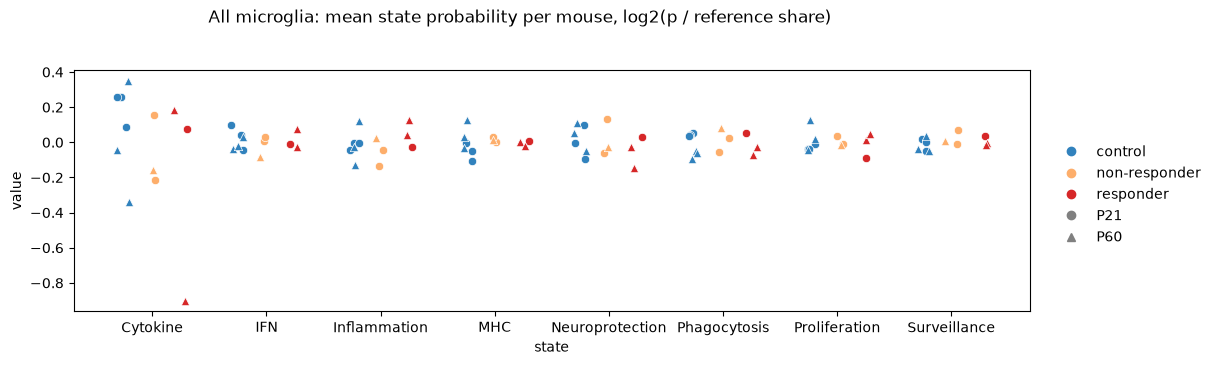

In [4]:
m_all = mouse_means(P)
omni_all = omnibus(m_all, 'all microglia')
display(omni_all.round(4))

res_all = test_means(m_all)
res_all.to_csv(f'{RES}/test_state_prob_all_microglia.csv', index=False)
display(res_all.sort_values(['comparison', 'p_perm']).round(4))
strip_states(np.log2(m_all / prior), 'All microglia: mean state probability per mouse, log2(p / reference share)',
             'state_prob_per_mouse.png')

## 2. Per compartment
Primary: compartments 3 and 10 (pre-specified). The omnibus test over all compartments is exploratory (BH-FDR over
compartments within each design).

In [4]:
m_comp = mouse_means(P, by=COMP)
order = sorted(q.obs[COMP].cat.categories, key=int)
omni_comp = pd.concat([omnibus(m_comp.xs(c, level=COMP), c) for c in order], ignore_index=True)
omni_comp = cs.add_fdr(omni_comp, cols=['p_perm'], family='design')
omni_comp['primary'] = omni_comp['scope'].isin(PRIMARY)
omni_comp.to_csv(f'{RES}/permanova_state_profile_per_compartment.csv', index=False)
display(omni_comp[omni_comp['primary']].round(4))
display(omni_comp.pivot(index='scope', columns='design', values='p_perm').reindex(order).round(4))

,scope,design,n_mice,pseudo_F,p_perm,n_perm,padj_perm,primary
6,3,mtDSB vs control,12,2.3880,0.1150,400,0.2475,True
7,3,responder vs control,9,8.7329,0.0119,84,0.0214,True
8,3,control / non-responder / responder,12,6.3628,0.0081,3600,0.0250,True
19,10,mtDSB vs control,12,1.3707,0.2700,400,0.3713,True
20,10,responder vs control,9,0.5644,0.7619,84,0.7619,True
21,10,control / non-responder / responder,12,0.7270,0.7506,3600,0.7506,True


design,control / non-responder / responder,mtDSB vs control,responder vs control
scope,,,
0,NaN,NaN,NaN
1,0.0083,0.0400,0.0119
2,0.0283,0.0700,0.0119
3,0.0081,0.1150,0.0119
4,0.0078,0.2300,0.0119
5,NaN,NaN,NaN
6,0.0550,0.0250,0.0238
7,0.0133,0.0650,0.0119
8,NaN,0.5556,NaN


In [5]:
res_comp = test_means(m_comp, by=COMP)
res_comp['primary'] = res_comp['scope'].isin(PRIMARY)
res_comp.to_csv(f'{RES}/test_state_prob_per_compartment.csv', index=False)
display(res_comp[res_comp['primary']].sort_values(['comparison', 'scope', 'p_perm']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, name in zip(axes, COMPARISONS):
    r = res_comp[res_comp['comparison'] == name]
    E = r.pivot(index='state', columns='scope', values='effect').reindex(columns=order)
    Pv = r.pivot(index='state', columns='scope', values='p_perm').reindex(columns=order)
    sns.heatmap(E, cmap='RdBu_r', center=0, annot=Pv.map(lambda p: '*' if p <= 0.02 else ''), fmt='', ax=ax,
                cbar_kws={'label': 'difference in mean probability'})
    ax.set_title(f'{name} (* raw p <= 0.02)')
fig.tight_layout()
fig.savefig(f'{RES}/state_prob_per_compartment_effect.png', dpi=150, bbox_inches='tight')

for comp in PRIMARY:
    strip_states(np.log2(m_comp.xs(comp, level=COMP) / prior),
                 f'Compartment {comp}: log2(p / reference share) per mouse', f'state_prob_comp{comp}_per_mouse.png')

NameError: name 'm_comp' is not defined

## 3. Microglia near DA-oligodendrocytes
For each microglia: distance to the nearest DA-OL in the same section. 
Per mouse: mean state probability within 50 µm minus beyond 50 µm. 
"Reactive" = 1 − p(Surveillance).

DA-OLs sit mainly in white matter and thalamus, so "near" microglia are also in different regions than "far" ones, and
regions differ in baseline microglial state. The **within-compartment** version compares near and far microglia inside
the same compartment (min 10 near and 10 far), then averages over compartments weighted by the near microglia. 
Problem: controls have few DA-OLs, so some drop out. 

In [6]:
with h5py.File(FULL, 'r') as h:
    ct_all = np.asarray(read_elem(h[f'obs/{CT_WORK}']))
    smp_all = np.asarray(read_elem(h[f'obs/{SAMPLE}']))
    xy_all = h['obsm/spatial'][:]
is_da = ct_all == 'DA-Oligodendrocytes'

dist = np.full(q.n_obs, np.nan)
for s in info.index:
    da_xy = xy_all[is_da & (smp_all == s)]
    m = (q.obs[SAMPLE] == s).values
    if len(da_xy) >= 20:
        dist[m] = cKDTree(da_xy).query(q.obsm['spatial'][m])[0]
near = dist <= RADIUS
has_dist = ~np.isnan(dist)
smp, comp_of = q.obs[SAMPLE].values, q.obs[COMP].astype(str).values


def near_far(values, within_comp=True, min_n=10):
    # per mouse: mean(values | near) - mean(values | far), optionally within compartments (weighted by n near)
    out, n_near = {}, {}
    for s in info.index:
        ms = (smp == s) & has_dist
        parts, weights = [], []
        for c in (np.unique(comp_of[ms]) if within_comp else [None]):
            m = ms & (comp_of == c) if c is not None else ms
            nn, ff = m & near, m & ~near
            if nn.sum() >= min_n and ff.sum() >= min_n:
                parts.append(values[nn].mean() - values[ff].mean())
                weights.append(nn.sum())
        if parts:
            out[s] = (pd.concat(parts, axis=1) * np.array(weights)).sum(1) / sum(weights)
            n_near[s] = sum(weights)
    return pd.DataFrame(out).T, pd.Series(n_near, name='n_near')


vals = P.assign(reactive=1 - P['Surveillance'])
near_res, near_omni = [], []
for label, within in [('within compartment', True), ('raw', False)]:
    d, n_near = near_far(vals, within_comp=within)
    d.join(n_near).join(info[[COND, RESP]]).to_csv(f'{RES}/state_prob_near_minus_far_DA_OL_{label.split()[0]}.csv')
    near_res.append(test_means(d).assign(version=label))
    near_omni.append(omnibus(d[STATES], f'near - far ({label})', transform=None))
    if within:
        display(d.join(n_near).join(info[[COND, RESP]]).round(4))
near_omni = pd.concat(near_omni, ignore_index=True)
near_res = pd.concat(near_res, ignore_index=True)
near_res.to_csv(f'{RES}/test_state_prob_near_DA_OL.csv', index=False)
display(near_omni.round(4))
display(near_res[near_res['version'] == 'within compartment'].sort_values(['comparison', 'p_perm']).round(4))

,Cytokine,IFN,Inflammation,MHC,Neuroprotection,Phagocytosis,Proliferation,Surveillance,reactive,n_near,condition,responder_status
RB4350,0.0043,-0.0023,-0.0221,0.0109,0.0010,0.0382,-0.0109,-0.0192,0.0192,116,control,control
RB4401,0.0012,-0.0039,-0.0259,0.0172,0.0111,0.0397,0.0029,-0.0424,0.0424,1123,mtDSB,responder
RB4403,-0.0017,0.0078,-0.0082,0.0059,0.0083,0.0133,0.0060,-0.0314,0.0314,83,mtDSB,non-responder
RB4405,0.0013,0.0034,-0.0237,0.0143,0.0109,0.0033,0.0143,-0.0238,0.0238,2033,mtDSB,responder
RB4498,0.0053,0.0326,-0.0304,-0.0047,-0.0113,-0.0126,0.0201,0.0010,-0.0010,48,control,control
RB4620,0.0044,0.0077,-0.0202,-0.0048,0.0414,0.0017,-0.0093,-0.0208,0.0208,43,control,control
RB4627,0.0007,-0.0042,-0.0144,0.0161,0.0008,0.0224,0.0096,-0.0310,0.0310,994,mtDSB,responder
RB4653,-0.0018,-0.0045,-0.0270,0.0213,0.0208,0.0463,-0.0213,-0.0338,0.0338,34,mtDSB,non-responder
RB4658,0.0013,-0.0139,0.0155,-0.0261,0.0297,0.0306,-0.0190,-0.0182,0.0182,14,control,control
RB4676,0.0004,0.0107,-0.0026,0.0090,-0.0015,0.0086,-0.0106,-0.0140,0.0140,90,control,control


,scope,design,n_mice,pseudo_F,p_perm,n_perm
0,near - far (within compartment),mtDSB vs control,10,1.7412,0.1300,100
1,near - far (within compartment),responder vs control,8,1.3808,0.2857,56
2,near - far (within compartment),control / non-responder / responder,10,0.9607,0.4483,600
3,near - far (raw),mtDSB vs control,12,4.2665,0.0400,400
4,near - far (raw),responder vs control,9,13.6378,0.0119,84
5,near - far (raw),control / non-responder / responder,12,6.4321,0.0033,3600


,comparison,scope,state,mean_ref,mean_treat,effect,p_perm,n_perm,n_treat,n_ref,padj_perm,version
7,mtDSB vs control,all microglia,Surveillance,-0.0142,-0.0325,-0.0191,0.0100,100,5,5,0.0450,within compartment
8,mtDSB vs control,all microglia,reactive,0.0142,0.0325,0.0191,0.0100,100,5,5,0.0450,within compartment
0,mtDSB vs control,all microglia,Cytokine,0.0032,-0.0001,-0.0036,0.0200,100,5,5,0.0600,within compartment
3,mtDSB vs control,all microglia,MHC,-0.0031,0.0150,0.0177,0.0600,100,5,5,0.1350,within compartment
1,mtDSB vs control,all microglia,IFN,0.0070,-0.0003,-0.0093,0.2700,100,5,5,0.4650,within compartment
5,mtDSB vs control,all microglia,Phagocytosis,0.0133,0.0250,0.0133,0.3100,100,5,5,0.4650,within compartment
2,mtDSB vs control,all microglia,Inflammation,-0.0120,-0.0198,-0.0056,0.5500,100,5,5,0.6300,within compartment
6,mtDSB vs control,all microglia,Proliferation,-0.0059,0.0023,0.0051,0.5600,100,5,5,0.6300,within compartment
4,mtDSB vs control,all microglia,Neuroprotection,0.0119,0.0104,0.0014,0.8600,100,5,5,0.8600,within compartment
16,responder vs control,all microglia,Surveillance,-0.0142,-0.0324,-0.0182,0.0179,56,3,5,0.0804,within compartment


## 4. Robustness: a classifier instead of Tangram
Multinomial logistic regression trained on the atlas microglia (same subsample, same kind of training genes), each gene
z-scored within its own dataset to reduce the platform shift (scRNA-seq vs Xenium). Its probabilities are summarised
and tested exactly like the Tangram ones. A result is considered robust when both methods agree in direction and both
have p ≤ 0.05. Takes a few minutes (atlas loading + fit).

In [7]:
from sklearn.linear_model import LogisticRegression

atlas = ad.read_h5ad(ATLAS, backed='r')
aobs = atlas.obs[atlas.obs['Subclass_label'] == 'Microglia']
keep = (aobs.groupby('Module_label', observed=True, group_keys=False)
        .apply(lambda d: d.sample(min(len(d), 3000), random_state=0)).index)
shared = [g for g in q.var_names if g in set(atlas.var_names)]
ref = atlas[keep, shared].to_memory()
sc.tl.rank_genes_groups(ref, 'Module_label', method='wilcoxon', n_genes=100)
rg = sc.get.rank_genes_groups_df(ref, group=None)
genes = sorted(set(rg.loc[rg['logfoldchanges'] > 0.5, 'names']))


def zscore(X):
    X = np.asarray(X.todense()) if hasattr(X, 'todense') else np.asarray(X)
    return (X - X.mean(0)) / (X.std(0) + 1e-6)


clf = LogisticRegression(max_iter=2000, class_weight='balanced', C=0.1)
clf.fit(zscore(ref[:, genes].X), ref.obs['Module_label'].astype(str))
P_lr = pd.DataFrame(clf.predict_proba(zscore(q[:, genes].X)), index=q.obs_names, columns=clf.classes_)[STATES]
print('training genes:', len(genes))
print('per-cell correlation, Tangram vs classifier:',
      pd.Series({s: np.corrcoef(P[s], P_lr[s])[0, 1] for s in STATES}).round(2).to_dict())

/tmp/ipykernel_171771/1342882480.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(len(d), 3000), random_state=0)).index)


training genes: 541
per-cell correlation, Tangram vs classifier: {'Cytokine': 0.22, 'IFN': 0.38, 'Inflammation': 0.41, 'MHC': 0.48, 'Neuroprotection': 0.23, 'Phagocytosis': 0.37, 'Proliferation': 0.44, 'Surveillance': 0.38}


In [8]:
def all_tests(Pm):
    # the same tests as sections 1-3 for one probability matrix
    out = [test_means(mouse_means(Pm)),
           test_means(mouse_means(Pm, by=COMP), by=COMP).query('scope in @PRIMARY')]
    d, _ = near_far(Pm.assign(reactive=1 - Pm['Surveillance']), within_comp=True)
    out.append(test_means(d).assign(scope='near - far DA-OL'))
    return pd.concat(out, ignore_index=True)[['comparison', 'scope', 'state', 'effect', 'p_perm']]


both = all_tests(P).merge(all_tests(P_lr), on=['comparison', 'scope', 'state'], suffixes=('_tangram', '_classifier'))
both['robust'] = ((np.sign(both['effect_tangram']) == np.sign(both['effect_classifier']))
                  & (both['p_perm_tangram'] <= 0.05) & (both['p_perm_classifier'] <= 0.05))
both.to_csv(f'{RES}/tangram_vs_classifier_tests.csv', index=False)
display(both[(both['p_perm_tangram'] <= 0.05) | (both['p_perm_classifier'] <= 0.05)]
        .sort_values(['scope', 'comparison', 'state']).round(4))

omni_lr = pd.concat([omnibus(mouse_means(P_lr), 'all microglia')] +
                    [omnibus(mouse_means(P_lr, by=COMP).xs(c, level=COMP), c) for c in PRIMARY], ignore_index=True)
display(omni_lr.round(4))

,comparison,scope,state,effect_tangram,p_perm_tangram,effect_classifier,p_perm_classifier,robust
33,mtDSB vs control,10,IFN,0.0064,0.3000,0.0230,0.0250,False
24,responder vs control,3,Cytokine,0.0007,0.7619,0.0274,0.0119,False
25,responder vs control,3,IFN,-0.0005,0.9048,-0.0494,0.0119,False
26,responder vs control,3,Inflammation,-0.0415,0.0119,-0.0878,0.0119,True
27,responder vs control,3,MHC,0.0330,0.0238,0.0148,0.6429,False
28,responder vs control,3,Neuroprotection,0.0253,0.0119,0.0182,0.0119,True
29,responder vs control,3,Phagocytosis,0.0532,0.0119,0.1423,0.0119,True
31,responder vs control,3,Surveillance,-0.0622,0.0119,-0.0330,0.0119,True
7,mtDSB vs control,all microglia,Surveillance,0.0028,0.2300,-0.0178,0.0050,False
8,responder vs control,all microglia,Cytokine,-0.0020,0.3333,0.0067,0.0119,False


,scope,design,n_mice,pseudo_F,p_perm,n_perm
0,all microglia,mtDSB vs control,12,1.9688,0.1650,400
1,all microglia,responder vs control,9,7.8215,0.0119,84
2,all microglia,control / non-responder / responder,12,4.8278,0.0036,3600
3,3,mtDSB vs control,12,2.8842,0.0950,400
4,3,responder vs control,9,16.3066,0.0119,84
5,3,control / non-responder / responder,12,9.6473,0.0086,3600
6,10,mtDSB vs control,12,1.3697,0.2650,400
7,10,responder vs control,9,2.3853,0.0595,84
8,10,control / non-responder / responder,12,1.5672,0.1850,3600


In [ ]:
# compartment 3: per-mouse mean probabilities, Tangram vs classifier
a = mouse_means(P, by=COMP).xs('3', level=COMP)
b = mouse_means(P_lr, by=COMP).xs('3', level=COMP)
grp = info.loc[a.index, RESP].astype(str).to_numpy()
tps = info.loc[a.index, TP].astype(str).to_numpy()
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, st in zip(axes.ravel(), STATES):
    for g_, col in PALETTE.items():
        for tp, mk in TP_MARKERS.items():
            k = (grp == g_) & (tps == tp)
            ax.scatter(a.loc[k, st], b.loc[k, st], color=col, marker=mk, label=f'{g_} {tp}', s=40)
    ax.set_title(f'{st}  r = {np.corrcoef(a[st], b[st])[0, 1]:.2f}', fontsize=10)
    ax.set_xlabel('Tangram'); ax.set_ylabel('classifier')
axes[0, 0].legend(fontsize=7)
fig.suptitle('Compartment 3: mean state probability per mouse, two methods', y=1.01)
fig.tight_layout()
fig.savefig(f'{RES}/tangram_vs_classifier_comp3.png', dpi=150, bbox_inches='tight')

## 5. Results table for the record

In [10]:
summary = pd.concat([omni_all, omni_comp[omni_comp['primary']].drop(columns=['padj_perm', 'primary']), near_omni],
                    ignore_index=True)
summary.to_csv(f'{RES}/permanova_summary.csv', index=False)
summary.round(4)

,scope,design,n_mice,pseudo_F,p_perm,n_perm
0,all microglia,mtDSB vs control,12,1.2143,0.2900,400
1,all microglia,responder vs control,9,1.1442,0.3214,84
2,all microglia,control / non-responder / responder,12,0.7449,0.5367,3600
3,3,mtDSB vs control,12,2.3880,0.1150,400
4,3,responder vs control,9,8.7329,0.0119,84
5,3,control / non-responder / responder,12,6.3628,0.0081,3600
6,10,mtDSB vs control,12,1.3707,0.2700,400
7,10,responder vs control,9,0.5644,0.7619,84
8,10,control / non-responder / responder,12,0.7270,0.7506,3600
9,near - far (within compartment),mtDSB vs control,10,1.7412,0.1300,100


## 7. Primary analysis: validated states, classifier
The validation (`05_classifier_validation.ipynb`) keeps only the
states that pass both checks there (separable at Xenium depth and correlated with held-out marker genes on the Xenium
microglia):
- **Surveillance** (homeostatic);
- **DAM-like** = Phagocytosis + Neuroprotection, which cannot be separated at Xenium depth;
- **MHC**: note that the atlas MHC module is mostly MHC-I and core microglial genes

IFN, Inflammation, Proliferation and Cytokine are not interpreted

Scopes: all microglia; compartments 3 and 10 (pre-specified); 4 (thalamus, exploratory). BH-FDR over the
12 tests (3 states × 4 scopes) of each comparison. The same tests on the Tangram probabilities are shown for comparison.

In [7]:
VALIDATED = {'Surveillance': ['Surveillance'], 'DAM-like': ['Phagocytosis', 'Neuroprotection'], 'MHC': ['MHC']}
P_cls = pd.read_csv('../data/microglia_classifier_probs.csv', index_col=0).loc[q.obs_names]
V_cls = pd.DataFrame({k: P_cls[v].sum(1) for k, v in VALIDATED.items()})
V_tg = pd.DataFrame({k: P[v].sum(1) for k, v in VALIDATED.items()})


def validated_tests(V, method):
    res = [test_means(mouse_means(V)).assign(scope='all microglia')]
    mc = mouse_means(V, by=COMP)
    for c in ['3', '4', '10']:
        res.append(test_means(mc.xs(c, level=COMP)).assign(scope=c))
    r = pd.concat(res, ignore_index=True).drop(columns='padj_perm')
    return cs.add_fdr(r, cols=['p_perm'], family='comparison').assign(method=method)


val = pd.concat([validated_tests(V_cls, 'classifier'), validated_tests(V_tg, 'Tangram')], ignore_index=True)
val.to_csv(f'{RES}/test_validated_states.csv', index=False)
wide = val.pivot_table(index=['comparison', 'scope', 'state'], columns='method', values=['effect', 'p_perm', 'padj_perm'])
wide.columns = [f'{a} ({b})' for a, b in wide.columns]
wide['agree'] = (np.sign(wide['effect (classifier)']) == np.sign(wide['effect (Tangram)'])) & \
                (wide['p_perm (classifier)'] <= 0.05) & (wide['p_perm (Tangram)'] <= 0.05)
wide.round(4)

effect (Tangram)  \
comparison           scope         state                            
mtDSB vs control     10            DAM-like               -0.0008   
                                   MHC                     0.0099   
                                   Surveillance            0.0030   
                     3             DAM-like                0.0381   
                                   MHC                     0.0196   
                                   Surveillance           -0.0313   
                     4             DAM-like                0.0240   
                                   MHC                     0.0068   
                                   Surveillance           -0.0172   
                     all microglia DAM-like               -0.0011   
                                   MHC                     0.0006   
                                   Surveillance            0.0028   
responder vs control 10            DAM-like               -0.0023   
                                   MHC                     0.0029   
                                   Surveillance            0.0047   
                     3             DAM-like                0.0784   
                                   MHC                     0.0330   
                                   Surveillance           -0.0622   
                     4             DAM-like                0.0480   
                                   MHC                     0.0183   
                                   Surveillance           -0.0458   
                     all microglia DAM-like               -0.0051   
                                   MHC                    -0.0001   
                                   Surveillance            0.0019   

                                                 effect (classifier)  \
comparison           scope         state                               
mtDSB vs control     10            DAM-like                   0.0177   
                                   MHC                       -0.0042   
                                   Surveillance              -0.0066   
                     3             DAM-like                   0.0820   
                                   MHC                       -0.0207   
                                   Surveillance              -0.0184   
                     4             DAM-like                   0.0501   
                                   MHC                        0.0192   
                                   Surveillance              -0.0263   
                     all microglia DAM-like                   0.0125   
                                   MHC                        0.0027   
                                   Surveillance              -0.0159   
responder vs control 10            DAM-like                   0.0503   
                                   MHC                        0.0028   
                                   Surveillance              -0.0117   
                     3             DAM-like                   0.1668   
                                   MHC                        0.0000   
                                   Surveillance              -0.0307   
                     4             DAM-like                   0.1465   
                                   MHC                        0.0709   
                                   Surveillance              -0.0527   
                     all microglia DAM-like                   0.0481   
                                   MHC                        0.0316   
                                   Surveillance              -0.0237   

                                                 p_perm (Tangram)  \
comparison           scope         state                            
mtDSB vs control     10            DAM-like                0.9550   
                                   MHC                     0.2650   
                                   Surveillance            0.7600   
                     3             D

## 8. Conclusions (run of 2026-10-22)

**Main result:** In responders, microglia in the globus pallidus / internal capsule (compartment 3) and the thalamus
(compartment 4) leave the surveillance (homeostatic) state and move to a DAM-like state (the Phagocytosis +
Neuroprotection modules of the Prinz atlas). Both changes, in both compartments: p = 0.012 (the smallest possible with
3 vs 6 mice), FDR 0.029 with the classifier and 0.036 with Tangram. All three responders lie outside the control range.

**Supporting evidence:** The same shift is visible gene by gene in the microglial pseudobulk DE and GSEA (notebooks 02,
02b): homeostatic genes down (P2ry12, Tmem119, Sall1), DAM / lysosome / lipid genes up (Cst7, Lpl, Cd9, Trem2, Itgax).
Compartments 3 and 4 also have the highest share of DA-oligodendrocytes and the largest increase in microglia. They
match where the CM analysis finds the strongest oligodendrocyte stress (finding 4), and where the IHC found immune cells
(internal capsule / thalamus).

**Not supported**
- **Whole section**: the shift appears only with the classifier (Surveillance ↓ FDR 0.029, DAM-like ↑ FDR 0.048), not
  with Tangram, so it is weak and method-dependent.
- **Corpus callosum (10)**: no state shift with either method, although some DAM genes (Cst7, Cd74, Lpl) are up in the
  DE there.
- **MHC state**: no robust change (Tangram p = 0.024 in compartment 3, classifier p = 1.0). The atlas MHC module is
  mostly MHC-I and core microglial genes; the MHC-II increase (Cd74, H2-Aa) is a DE finding.
- **All 6 mtDSB vs controls**: same directions, nothing survives FDR (closest: Surveillance over the whole section,
  classifier, p = 0.005, FDR 0.06), diluted by the three non-responders.
- **Microglia near DA-OLs** (section 3): the difference is mostly regional, not local, with this readout.

**Why the classifier** Tangram maps atlas cells onto spatial cells by matching whole expression
profiles. With the Prinz atlas and Xenium microglia, it is a poor state caller:
- Each Xenium microglia receives a weighted mix of many atlas cells, so its state probabilities are averages. Across 8
  states the median top probability is 0.26, and 98% of cells stay below 0.5.
- The level of these probabilities is set by the composition of the atlas subsample.
- Tangram offers no direct way to check how well each state is recovered.
- The two datasets differ a lot: deep scRNA-seq from other disease models on one side, about 600 transcripts per cell on
  a 5k panel on the other, so similar states blur together.

A classifier avoids the first two problems and can be validated. Tangram is kept as an independent check.

**How the classifier works.**
- *Training*: a multinomial logistic regression is trained on 19,788 atlas microglia (at most 3,000 per state). It
  predicts the 8 atlas states from 541 atlas marker genes that are also on the Xenium panel.
- *Platform difference*: each gene is z-scored within its own dataset, so the model learns "higher or lower than usual in
  this dataset" and is less affected by the difference between scRNA-seq and Xenium.
- *Regularisation*: strong L2 regularisation spreads the weight over many genes, and balanced class weights keep rare
  states from being ignored.
- *Output*: for each Xenium microglia the model returns one probability per state, computed from that cell alone. The
  probabilities are averaged per mouse (and compartment) and compared between groups with exact permutation tests.
- *Validation* (notebook 05): cross-validation grouped by atlas sample, with test cells down-sampled to Xenium depth
  (balanced accuracy 0.54 vs 0.125 by chance; permutation null 0.12–0.13); and a check that each state's probability
  tracks held-out marker genes in the Xenium cells. Only states passing both are interpreted: Surveillance, DAM-like
  (Phagocytosis + Neuroprotection, which cannot be separated at Xenium depth) and MHC.

**Limits**
- Only 3 responders.
- The atlas states come from other disease models; none is mtDNA damage in oligodendrocytes.
- Probabilities are soft and not precise (overestimated) (notebook 05), so only differences between mice are interpreted, not levels.